# LAB 4 — BƯỚC B: BASELINE CONCATENATION

**Học phần:** CSE457 — Xử lý âm thanh và tiếng nói  
**Bám sát tài liệu:** Lab 4, **mục 4.2 (B)** và case study mục 5.3.  
**Đầu vào:** 32 file đã xử lý từ bước A: `lab4_data/units/*.wav` (16 từ × 2 candidate).

### Mục tiêu
1. Nhận một câu văn bản miền hẹp: **“Mời khách hàng số 23 đến quầy 5.”**
2. Chuẩn hóa số theo từng chữ số → 9 word-unit.
3. Chọn **một candidate cố định** (`_01.wav`) cho mỗi từ, ghép **trực tiếp** các waveform; **không cross-fade, không tối ưu unit, không thêm khoảng lặng**.
4. Lưu `audio_output/raw_concat.wav` và bảng các unit / biên nối.
5. Vẽ **waveform + spectrogram** (đường dọc tại biên) và phóng to **ít nhất 2 biên** để nghe, nhận xét click / mức âm / pitch jump / phổ.

> Không có file giọng nói được tạo sẵn trong notebook. Chỉ sử dụng WAV thật trong thư mục `lab4_data/units/` của bạn. Không được xem các chỉ số kỹ thuật là kết luận tự động về độ tự nhiên; phải nghe thực tế.

## 0. Chuẩn bị VS Code

Đặt notebook **ngang cấp** với `lab4_data`, ví dụ:

```text
Lab04_TTS/
├── Lab04_Buoc1_A_Dataset.ipynb
├── Lab04_Buoc2_B.ipynb           ← file này
├── lab4_data/
│   ├── metadata.csv
│   ├── source_provenance.csv     (nếu có)
│   └── units/
│       ├── moi_01.wav
│       ├── moi_02.wav
│       ├── khach_01.wav
│       └── ...
├── figures/
└── audio_output/
```

Nếu chưa cài các thư viện từ bước A, chạy trong Terminal của VS Code:

```powershell
python -m pip install numpy pandas matplotlib scipy soundfile ipython ipykernel
```

Chọn **Select Kernel** là Python environment bạn đã dùng để chạy bước A. Mở VS Code đúng thư mục dự án trước khi **Run All**.

In [1]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import stft
from IPython.display import display, Audio

SR = 16000
ROOT = Path.cwd().resolve()
DATA_DIR = ROOT / "lab4_data"
UNIT_DIR = DATA_DIR / "units"
METADATA_PATH = DATA_DIR / "metadata.csv"
PROVENANCE_PATH = DATA_DIR / "source_provenance.csv"
OUT_DIR = ROOT / "audio_output"
FIG_DIR = ROOT / "figures"

# Chỉ tạo thư mục output; KHÔNG tự tạo units/ để tránh làm mờ lỗi sai vị trí.
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

if not UNIT_DIR.is_dir():
    raise FileNotFoundError(
        f"Không thấy {UNIT_DIR}. Hãy mở VS Code đúng thư mục Lab04_TTS; "
        "đặt notebook cùng cấp với lab4_data/units."
    )
print("Project ROOT :", ROOT)
print("Unit folder  :", UNIT_DIR)
print("WAV files    :", len(list(UNIT_DIR.glob('*.wav'))))
print("Output folder:", OUT_DIR)

Project ROOT : C:\xulyamthanh\lab04_2351260688_NguyenNgocTien
Unit folder  : C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\lab4_data\units
WAV files    : 32
Output folder: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output


## 1. Chuẩn hóa câu và ánh xạ token → file

Lab sử dụng số kiểu **mã xếp hàng**, vì vậy `23` đọc **“hai ba”**, không đọc “hai mươi ba”.

Mỗi từ có slug tên file không dấu nhưng nhãn phải giữ nguyên dấu thanh tiếng Việt.

In [2]:
UNIT_NAMES = {
    "mời":"moi", "khách":"khach", "hàng":"hang", "số":"so",
    "không":"khong", "một":"mot", "hai":"hai", "ba":"ba",
    "bốn":"bon", "năm":"nam", "sáu":"sau", "bảy":"bay",
    "tám":"tam", "chín":"chin", "đến":"den", "quầy":"quay",
}
DIGIT = {"0":"không", "1":"một", "2":"hai", "3":"ba", "4":"bốn",
         "5":"năm", "6":"sáu", "7":"bảy", "8":"tám", "9":"chín"}

# Bản cố định làm baseline, không chọn candidate tối ưu ở bước này.
FIXED_TAKE = 1
TEST_SENTENCE = "Mời khách hàng số 23 đến quầy 5."


def normalize_text(text: str) -> list[str]:
    if not isinstance(text, str):
        raise TypeError("Đầu vào phải là văn bản (str)")
    text = unicodedata.normalize("NFC", text).lower().replace("_", " ")
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    tokens = text.split()
    output = []
    for token in tokens:
        if token.isdecimal():
            if any(ch not in DIGIT for ch in token):
                raise ValueError(f"Chỉ hỗ trợ chữ số ASCII 0–9: {token}")
            output.extend(DIGIT[ch] for ch in token)
        else:
            output.append(token)
    unknown = sorted(set(output) - set(UNIT_NAMES))
    if unknown:
        raise ValueError(f"Các từ ngoài inventory 16 từ: {unknown}")
    if not output:
        raise ValueError("Văn bản rỗng")
    return output

TOKENS = normalize_text(TEST_SENTENCE)
assert TOKENS == ["mời", "khách", "hàng", "số", "hai", "ba", "đến", "quầy", "năm"]
print("Input:", TEST_SENTENCE)
print("Tokens:", TOKENS)
print("Số token:", len(TOKENS))

Input: Mời khách hàng số 23 đến quầy 5.
Tokens: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']
Số token: 9


## 2. Kiểm tra inventory và speaker

- Bước A phải có **32 file** (mục tiêu), nhưng bước B cần ít nhất **16 file candidate 01** khác nhau.
- Chúng ta xác minh thực tế sample rate, số kênh, subtype của từng WAV bằng `soundfile`.
- Nếu `_01` của các từ thuộc **nhiều người nói**, notebook sẽ cảnh báo; điều này có thể gây thay đổi âm sắc đột ngột. **Không thay đổi candidate** ở baseline; việc chọn lại là nội dung bước C.

In [3]:
if METADATA_PATH.exists():
    metadata = pd.read_csv(METADATA_PATH, encoding="utf-8-sig")
    print(f"Đọc metadata: {len(metadata)} dòng")
else:
    metadata = pd.DataFrame()
    print("CẢNH BÁO: chưa tìm thấy metadata.csv; vẫn có thể ghép WAV theo tên file.")

speaker_lookup = {}
for table_path in [PROVENANCE_PATH, METADATA_PATH]:
    if not table_path.exists():
        continue
    info_df = pd.read_csv(table_path, encoding="utf-8-sig")
    if {"speaker", "file_path"}.issubset(info_df.columns):
        for row in info_df.itertuples(index=False):
            speaker_lookup[Path(row.file_path).name] = str(row.speaker)
    elif {"speaker", "filename"}.issubset(info_df.columns):
        for row in info_df.itertuples(index=False):
            speaker_lookup[str(row.filename)] = str(row.speaker)

inventory_rows = []
invalid = []
for label, slug in UNIT_NAMES.items():
    for take in (1, 2):
        name = f"{slug}_{take:02d}.wav"
        path = UNIT_DIR / name
        if not path.exists():
            invalid.append(f"Thiếu {name}")
            continue
        info = sf.info(path)
        inventory_rows.append({
            "label": label, "filename": name, "speaker": speaker_lookup.get(name, "unknown"),
            "sample_rate": info.samplerate, "channels": info.channels,
            "subtype": info.subtype, "duration_s": round(info.duration, 3),
        })
        if (info.samplerate != SR or info.channels != 1 or info.subtype != "PCM_16"):
            invalid.append(f"Sai định dạng {name}: sr={info.samplerate}, channels={info.channels}, subtype={info.subtype}")

inventory_check = pd.DataFrame(inventory_rows)
print(f"Tồn tại {len(inventory_check)}/32 file WAV mục tiêu")
if not inventory_check.empty:
    display(inventory_check)
if invalid:
    print("Các mục cần xử lý:")
    for issue in invalid: print("  -", issue)

# Chỉ chặn lỗi ảnh hưởng trực tiếp đến câu baseline này.
required_files = {f"{UNIT_NAMES[token]}_{FIXED_TAKE:02d}.wav" for token in TOKENS}
missing = sorted(required_files - set(inventory_check.filename if not inventory_check.empty else []))
if missing:
    raise FileNotFoundError(
        "Chưa đủ các WAV `_01` cho câu thử: " + ", ".join(missing) +
        ". Hãy chạy bước A hoặc kiểm tra thư mục units."
    )
used_info = inventory_check[inventory_check.filename.isin(required_files)]
wrong_format = used_info[
    (used_info.sample_rate != SR) |
    (used_info.channels != 1) |
    (used_info.subtype != "PCM_16")
]
if not wrong_format.empty:
    raise ValueError("Một số file dùng cho câu test chưa chuẩn 16 kHz/mono/PCM_16; chạy lại bước A.")
known_speakers = {s for s in used_info.speaker if s != "unknown"}
if len(known_speakers) > 1:
    print("⚠ CẢNH BÁO: các candidate 01 thuộc nhiều người nói:", sorted(known_speakers))
    print("   Đây là baseline cố định; bước C sẽ đánh giá lựa chọn candidate theo speaker/join cost.")
else:
    print("Speaker của các WAV sử dụng:", sorted(known_speakers) or "Chưa xác định")

Đọc metadata: 32 dòng
Tồn tại 32/32 file WAV mục tiêu


,label,filename,speaker,sample_rate,channels,subtype,duration_s
0,mời,moi_01.wav,lephuong,16000,1,PCM_16,0.500
1,mời,moi_02.wav,longtran,16000,1,PCM_16,0.750
2,khách,khach_01.wav,lephuong,16000,1,PCM_16,0.625
3,khách,khach_02.wav,longtran,16000,1,PCM_16,0.750
4,hàng,hang_01.wav,lephuong,16000,1,PCM_16,0.500
5,hàng,hang_02.wav,longtran,16000,1,PCM_16,0.625
6,số,so_01.wav,lephuong,16000,1,PCM_16,0.625
7,số,so_02.wav,longtran,16000,1,PCM_16,0.625
8,không,khong_01.wav,lephuong,16000,1,PCM_16,0.625
9,không,khong_02.wav,longtran,16000,1,PCM_16,0.625


Speaker của các WAV sử dụng: ['lephuong']


## 3. Ghép thẳng (không cross-fade) → `raw_concat.wav`

Với các đoạn âm thanh \(x_1,x_2,\ldots,x_K\), bản ghép trực tiếp là:

\[
y = x_1 \Vert x_2 \Vert \cdots \Vert x_K
\]

Ký hiệu \(\Vert\) là **phép nối các mảng sample**, không trộn và không overlap. Vị trí nối thứ \(j\) được ghi bằng **số mẫu cộng dồn** của các unit trước đó.

Notebook không match RMS lần nữa vì đã xử lý trong bước A; đây là baseline đơn giản, thuận tiện để đánh giá kỹ thuật smoothing ở bước C.

In [4]:
def load_unit(path: Path, sr: int = SR) -> np.ndarray:
    x, fs = sf.read(path, dtype="float32", always_2d=False)
    if fs != sr or x.ndim != 1:
        raise ValueError(f"Không phải WAV {sr} Hz mono: {path}")
    if len(x) < int(0.1 * sr):
        raise ValueError(f"Unit quá ngắn ({len(x)/sr:.3f}s): {path}")
    if not np.isfinite(x).all():
        raise ValueError(f"Giá trị bất thường trong {path}")
    return x


def stitch_sentence(sentence: str, fixed_take: int = FIXED_TAKE):
    tokens = normalize_text(sentence)
    pieces, selection, boundary_info = [], [], []
    count_samples = 0
    prev_x, prev_word, prev_file = None, None, None
    for i, word in enumerate(tokens):
        name = f"{UNIT_NAMES[word]}_{fixed_take:02d}.wav"
        path = UNIT_DIR / name
        if not path.is_file():
            raise FileNotFoundError(f"Thiếu candidate: {path}")
        x = load_unit(path)
        if prev_x is not None:
            boundary_info.append({
                "boundary_id": len(boundary_info) + 1,
                "previous_word": prev_word, "next_word": word,
                "previous_file": prev_file, "next_file": name,
                "sample_index": count_samples, "time_s": count_samples / SR,
            })
        selection.append({
            "position": i + 1, "word": word, "file": name,
            "speaker": speaker_lookup.get(name, "unknown"),
            "start_s": count_samples / SR,
            "end_s": (count_samples + len(x)) / SR,
            "duration_s": len(x) / SR,
        })
        pieces.append(x)
        count_samples += len(x)
        prev_x, prev_word, prev_file = x, word, name
    audio = np.concatenate(pieces).astype(np.float32)
    return audio, pd.DataFrame(selection), pd.DataFrame(boundary_info)


wave, selected_units, boundaries = stitch_sentence(TEST_SENTENCE)
output_file = OUT_DIR / "raw_concat.wav"
sf.write(output_file, wave, SR, subtype="PCM_16")
selected_units.to_csv(OUT_DIR / "baseline_selected_units.csv", index=False, encoding="utf-8-sig")
boundaries.to_csv(OUT_DIR / "baseline_boundaries.csv", index=False, encoding="utf-8-sig")

assert len(wave) == round(selected_units.duration_s.sum() * SR)
assert len(boundaries) == len(selected_units) - 1
print("Đã lưu:", output_file)
print("Duration (s):", round(len(wave) / SR, 3))
print("Số từ:", len(selected_units), " | Số biên nối:", len(boundaries))
print("Sample rate:", sf.info(output_file).samplerate, " | Subtype:", sf.info(output_file).subtype)
display(selected_units)
display(boundaries)
display(Audio(filename=str(output_file)))

Đã lưu: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\raw_concat.wav
Duration (s): 5.0
Số từ: 9  | Số biên nối: 8
Sample rate: 16000  | Subtype: PCM_16


,position,word,file,speaker,start_s,end_s,duration_s
0,1,mời,moi_01.wav,lephuong,0.000,0.500,0.500
1,2,khách,khach_01.wav,lephuong,0.500,1.125,0.625
2,3,hàng,hang_01.wav,lephuong,1.125,1.625,0.500
3,4,số,so_01.wav,lephuong,1.625,2.250,0.625
4,5,hai,hai_01.wav,lephuong,2.250,2.750,0.500
5,6,ba,ba_01.wav,lephuong,2.750,3.250,0.500
6,7,đến,den_01.wav,lephuong,3.250,3.875,0.625
7,8,quầy,quay_01.wav,lephuong,3.875,4.375,0.500
8,9,năm,nam_01.wav,lephuong,4.375,5.000,0.625


,boundary_id,previous_word,next_word,previous_file,next_file,sample_index,time_s
0,1,mời,khách,moi_01.wav,khach_01.wav,8000,0.500
1,2,khách,hàng,khach_01.wav,hang_01.wav,18000,1.125
2,3,hàng,số,hang_01.wav,so_01.wav,26000,1.625
3,4,số,hai,so_01.wav,hai_01.wav,36000,2.250
4,5,hai,ba,hai_01.wav,ba_01.wav,44000,2.750
5,6,ba,đến,ba_01.wav,den_01.wav,52000,3.250
6,7,đến,quầy,den_01.wav,quay_01.wav,62000,3.875
7,8,quầy,năm,quay_01.wav,nam_01.wav,70000,4.375


## 4. Vẽ waveform của toàn bộ câu, đánh dấu biên nối

Vạch đứt biểu thị thời điểm chuyển từ unit trước sang unit sau; nhãn tại giữa mỗi đoạn cho biết từ tương ứng. Lưu hình cho báo cáo và kiểm chứng độ dài câu.

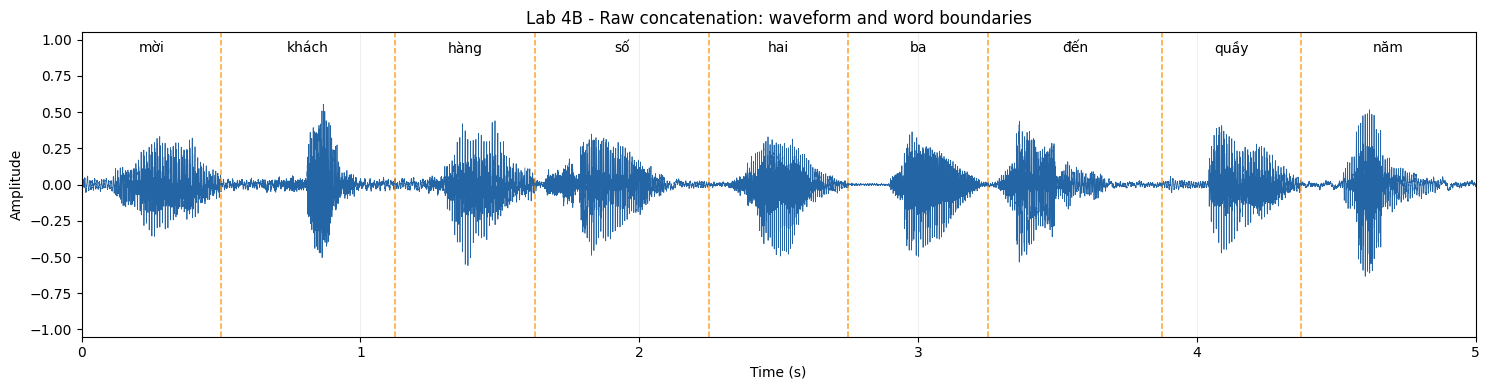

In [5]:
time_axis = np.arange(len(wave)) / SR
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(time_axis, wave, color="#2465A5", linewidth=0.55)
for r in boundaries.itertuples(index=False):
    ax.axvline(r.time_s, color="darkorange", linestyle="--", linewidth=1.1, alpha=0.8)
for r in selected_units.itertuples(index=False):
    ax.text((r.start_s + r.end_s) / 2, 0.97, r.word,
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
ax.set(xlabel="Time (s)", ylabel="Amplitude",
       title="Lab 4B - Raw concatenation: waveform and word boundaries")
ax.set_xlim(0, len(wave) / SR)
ax.set_ylim(-1.05, 1.05)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "b_raw_waveform_boundaries.png", dpi=170, bbox_inches="tight")
plt.show()

## 5. Vẽ spectrogram của toàn bộ câu

Sử dụng **STFT**: cửa sổ Hann 25 ms (= 400 mẫu), bước nhảy 10 ms (= 160 mẫu), `nfft=512`. Vẽ phổ biên độ ở thang log/dB và đánh dấu biên nối.

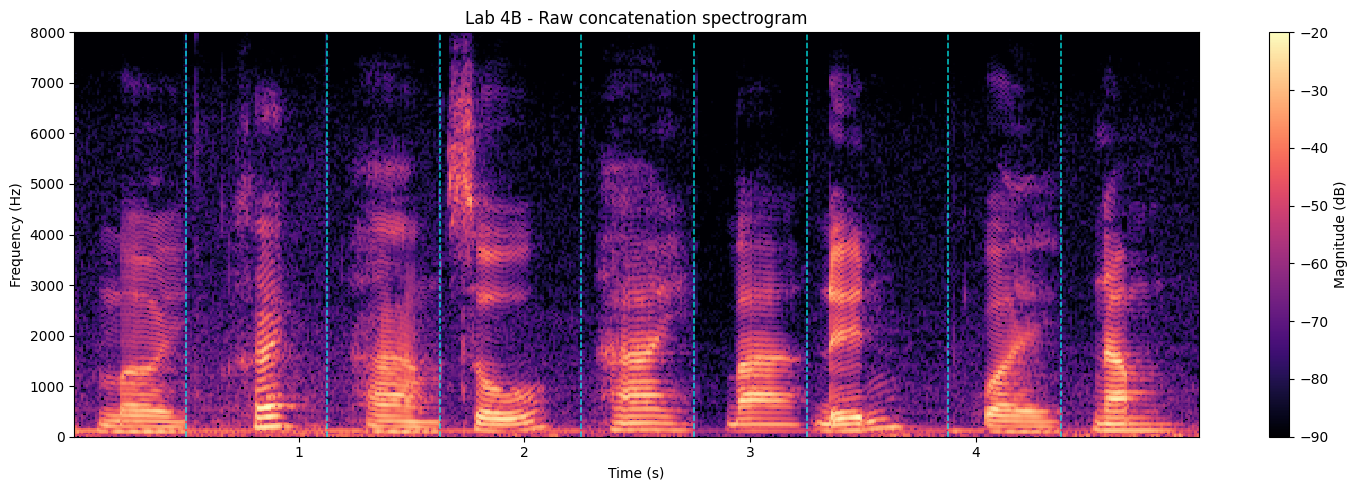

In [6]:
def get_spectrogram(x: np.ndarray, sr: int = SR):
    f, t, z = stft(x, fs=sr, window="hann", nperseg=400,
                   noverlap=240, nfft=512, boundary=None, padded=False)
    mag = np.abs(z)
    db = 20 * np.log10(np.maximum(mag, 1e-8))
    return f, t, db

freqs, times, db = get_spectrogram(wave)
fig, ax = plt.subplots(figsize=(15, 5))
plot = ax.pcolormesh(times, freqs, db, shading="auto", cmap="magma", vmin=-90, vmax=-20)
fig.colorbar(plot, ax=ax, label="Magnitude (dB)")
for r in boundaries.itertuples(index=False):
    ax.axvline(r.time_s, color="cyan", linestyle="--", linewidth=1.1, alpha=0.8)
ax.set(xlabel="Time (s)", ylabel="Frequency (Hz)",
       title="Lab 4B - Raw concatenation spectrogram")
ax.set_ylim(0, 8000)
fig.tight_layout()
fig.savefig(FIG_DIR / "b_raw_spectrogram_boundaries.png", dpi=170, bbox_inches="tight")
plt.show()

## 6. Tính các chỉ số **chẩn đoán** ở từng biên nối

Dựa trên mục 4.2: lắng nghe click, chênh năng lượng, pitch jump hoặc thay đổi phổ. Để hỗ trợ **xác định biên cần nghe kỹ**, ta đo:

- `abs_sample_jump`: \(\lvert y[k]-y[k-1]\rvert\), độ nhảy giữa **hai sample** sát biên.
- `rms_gap_db`: chênh RMS của 25 ms cuối/trước; đo tại biên, không phải RMS toàn từ.
- `spectral_mismatch_db2`: sai lệch bình phương trung bình log-magnitude của 25 ms cuối/đầu (gợi ý cho bước C).

**Quan trọng:** Các chỉ số này **không tự khẳng định** có click, pitch jump hay giọng nghe không tự nhiên; các từ khác nhau thường có phổ khác nhau. Cần **nghe và quan sát waveform/spectrogram** để nhận xét. Không áp dụng cross-fade ở bước B.

In [7]:
def root_mean_square(x: np.ndarray) -> float:
    return float(np.sqrt(np.mean(np.square(x.astype(np.float64))))) if len(x) else 0.0


def spectrum_log_mag(x: np.ndarray, nfft: int = 512) -> np.ndarray:
    w = np.hanning(len(x))
    return 20 * np.log10(np.maximum(np.abs(np.fft.rfft(x * w, n=nfft)), 1e-8))


def score_boundary(audio: np.ndarray, sample_index: int, sr: int = SR, ms: float = 25.0):
    n = round(sr * ms / 1000)
    if sample_index < n or (len(audio) - sample_index) < n:
        raise ValueError("Không đủ 25 ms ở hai phía biên")
    left, right = audio[sample_index-n:sample_index], audio[sample_index:sample_index+n]
    jump = float(audio[sample_index] - audio[sample_index - 1])
    rms_left = root_mean_square(left)
    rms_right = root_mean_square(right)
    dspec = spectrum_log_mag(left) - spectrum_log_mag(right)
    return {
        "sample_jump": jump,
        "abs_sample_jump": abs(jump),
        "rms_left": rms_left,
        "rms_right": rms_right,
        "rms_gap_db": float(20 * np.log10((rms_right + 1e-9) / (rms_left + 1e-9))),
        "spectral_mismatch_db2": float(np.mean(dspec**2)),
    }

boundary_metrics = boundaries.copy()
for col in ["sample_jump", "abs_sample_jump", "rms_left", "rms_right", "rms_gap_db", "spectral_mismatch_db2"]:
    boundary_metrics[col] = [score_boundary(wave, int(k))[col] for k in boundaries.sample_index]

boundary_metrics.to_csv(OUT_DIR / "baseline_boundary_diagnostics.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", OUT_DIR / "baseline_boundary_diagnostics.csv")
display(boundary_metrics.round(4))
print("Biên có độ nhảy sample lớn nhất:")
display(boundary_metrics.nlargest(2, "abs_sample_jump")[[
    "boundary_id", "previous_word", "next_word", "time_s", "abs_sample_jump", "rms_gap_db"
]].round(4))

Đã lưu: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\baseline_boundary_diagnostics.csv


,boundary_id,previous_word,next_word,previous_file,next_file,sample_index,time_s,sample_jump,abs_sample_jump,rms_left,rms_right,rms_gap_db,spectral_mismatch_db2
0,1,mời,khách,moi_01.wav,khach_01.wav,8000,0.500,0.0515,0.0515,0.0474,0.0158,-9.5343,97.1818
1,2,khách,hàng,khach_01.wav,hang_01.wav,18000,1.125,-0.0333,0.0333,0.0187,0.0189,0.0978,58.8621
2,3,hàng,số,hang_01.wav,so_01.wav,26000,1.625,-0.0346,0.0346,0.0496,0.0120,-12.2989,90.6214
3,4,số,hai,so_01.wav,hai_01.wav,36000,2.250,-0.0135,0.0135,0.0119,0.0082,-3.2535,75.9080
4,5,hai,ba,hai_01.wav,ba_01.wav,44000,2.750,0.0109,0.0109,0.0126,0.0032,-12.0272,103.0525
5,6,ba,đến,ba_01.wav,den_01.wav,52000,3.250,0.0081,0.0081,0.0082,0.0079,-0.2367,108.7667
6,7,đến,quầy,den_01.wav,quay_01.wav,62000,3.875,-0.0038,0.0038,0.0079,0.0134,4.6146,64.0200
7,8,quầy,năm,quay_01.wav,nam_01.wav,70000,4.375,-0.0080,0.0080,0.0268,0.0095,-8.9723,80.3189


Biên có độ nhảy sample lớn nhất:


,boundary_id,previous_word,next_word,time_s,abs_sample_jump,rms_gap_db
0,1,mời,khách,0.500,0.0515,-9.5343
2,3,hàng,số,1.625,0.0346,-12.2989


## 7. Phóng to waveform + spectrogram tại **2 biên nối**

Để lựa chọn vị trí kiểm tra có hệ thống, notebook chọn 2 biên có `abs_sample_jump` lớn nhất và vẽ vùng ±120 ms quanh từng biên. Đây là **biên để khảo sát**, không phải khẳng định trước rằng có click. Bạn cần nghe đoạn tương ứng trong `raw_concat.wav`.

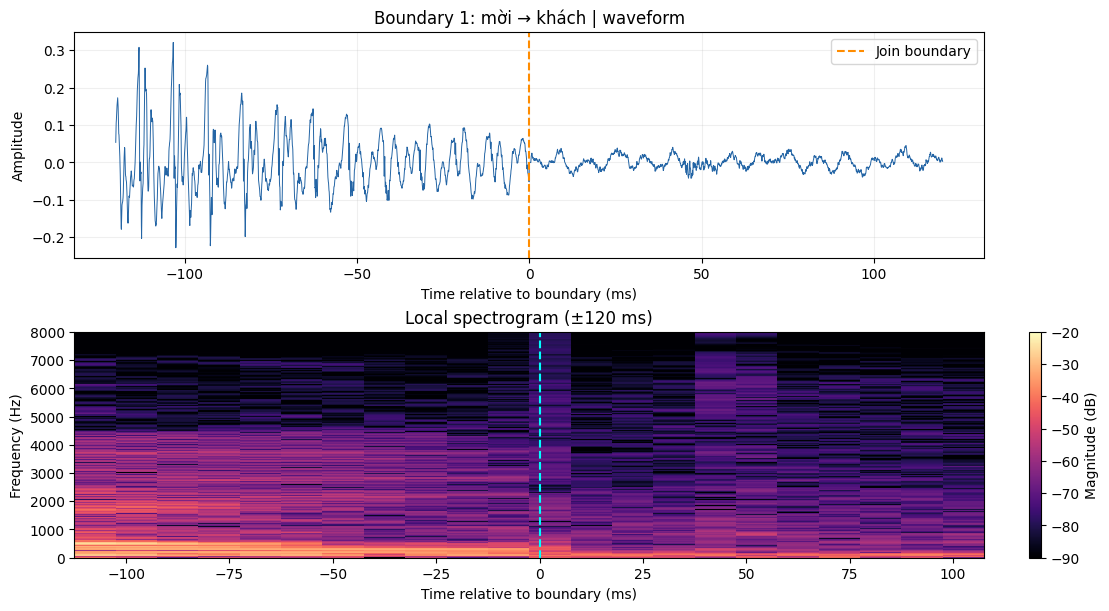

Đã lưu: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\figures\b_boundary_01_zoom.png


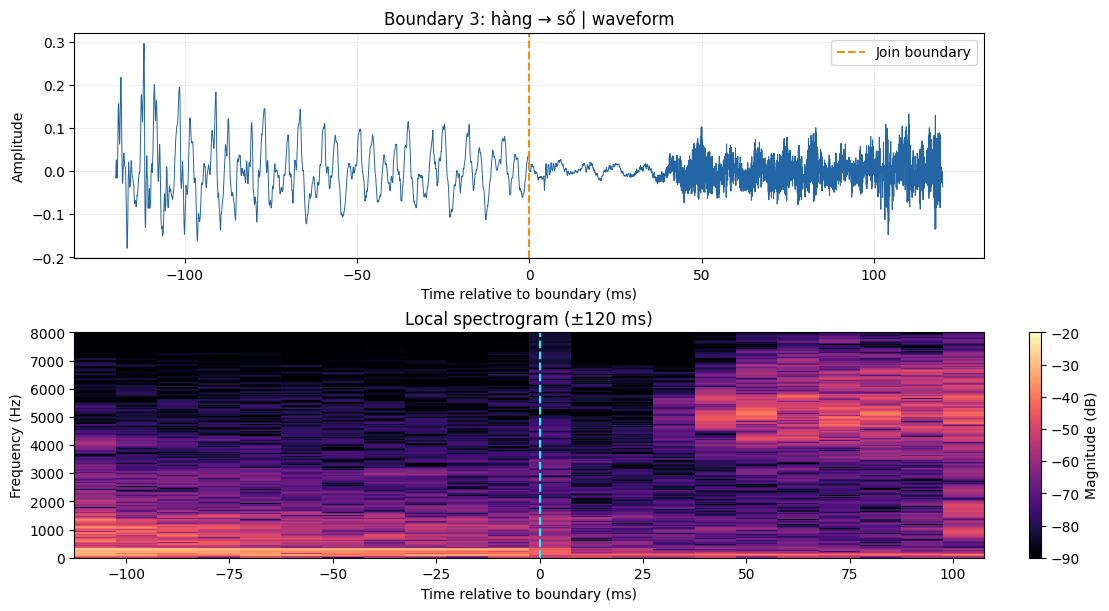

Đã lưu: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\figures\b_boundary_03_zoom.png


In [8]:
worst2 = boundary_metrics.nlargest(2, "abs_sample_jump").sort_values("boundary_id")
for r in worst2.itertuples(index=False):
    s0 = max(0, r.sample_index - round(0.12 * SR))
    s1 = min(len(wave), r.sample_index + round(0.12 * SR))
    clip = wave[s0:s1]
    local_t = (np.arange(s0, s1) - r.sample_index) / SR * 1000  # ms từ biên
    f, t, local_db = get_spectrogram(clip)
    relative_t = (t + s0 / SR - r.time_s) * 1000

    fig, axs = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
    axs[0].plot(local_t, clip, color="#2465A5", linewidth=0.7)
    axs[0].axvline(0, color="darkorange", linestyle="--", label="Join boundary")
    axs[0].set(xlabel="Time relative to boundary (ms)", ylabel="Amplitude",
               title=f"Boundary {r.boundary_id}: {r.previous_word} → {r.next_word} | waveform")
    axs[0].legend(loc="upper right")
    axs[0].grid(alpha=0.2)
    pcm = axs[1].pcolormesh(relative_t, f, local_db, shading="auto", cmap="magma", vmin=-90, vmax=-20)
    axs[1].axvline(0, color="cyan", linestyle="--")
    axs[1].set(xlabel="Time relative to boundary (ms)", ylabel="Frequency (Hz)",
               title="Local spectrogram (±120 ms)")
    axs[1].set_ylim(0, 8000)
    fig.colorbar(pcm, ax=axs[1], label="Magnitude (dB)")
    save_path = FIG_DIR / f"b_boundary_{r.boundary_id:02d}_zoom.png"
    fig.savefig(save_path, dpi=170, bbox_inches="tight")
    plt.show()
    print("Đã lưu:", save_path)

## 8. Thử thêm 2 câu (tùy chọn, để dùng lại khi đánh giá 3 backend ở bước G)

Mọi câu đều phải chỉ sử dụng 16 từ trong inventory và chung quy tắc đọc chữ số. Bước B bắt buộc vẫn là `raw_concat.wav` của câu số 1.

In [9]:
TEST_SENTENCES = [
    TEST_SENTENCE,
    "Mời khách hàng số 17 đến quầy 2.",
    "Mời khách hàng số 90 đến quầy 8.",
]

rows = []
for i, sentence in enumerate(TEST_SENTENCES, start=1):
    yy, ss, bb = stitch_sentence(sentence)
    fn = f"raw_concat_test_{i:02d}.wav"
    sf.write(OUT_DIR / fn, yy, SR, subtype="PCM_16")
    rows.append({"test_id": i, "text": sentence,
                 "tokens": " | ".join(normalize_text(sentence)),
                 "filename": fn, "duration_s": len(yy)/SR, "num_boundaries": len(bb)})
tests = pd.DataFrame(rows)
tests.to_csv(OUT_DIR / "baseline_test_sentences.csv", index=False, encoding="utf-8-sig")
print("Đã xuất audio cho 3 câu thử (bản ghép thẳng, không smoothing).")
display(tests)

Đã xuất audio cho 3 câu thử (bản ghép thẳng, không smoothing).


,test_id,text,tokens,filename,duration_s,num_boundaries
0,1,Mời khách hàng số 23 đến quầy 5.,mời | khách | hàng | số | hai | ba | đến | quầ...,raw_concat_test_01.wav,5.000,8
1,2,Mời khách hàng số 17 đến quầy 2.,mời | khách | hàng | số | một | bảy | đến | qu...,raw_concat_test_02.wav,5.250,8
2,3,Mời khách hàng số 90 đến quầy 8.,mời | khách | hàng | số | chín | không | đến |...,raw_concat_test_03.wav,5.125,8


## 9. Tổng kết, tự nghe và nội dung cần viết trong báo cáo

**Đầu ra bắt buộc của mục B:**
- `audio_output/raw_concat.wav` — giọng tổng hợp bằng ghép nối trực tiếp, **không smoothing**.
- `figures/b_raw_waveform_boundaries.png` — waveform + vị trí các biên.
- `figures/b_raw_spectrogram_boundaries.png` — spectrogram + vị trí các biên.
- `figures/b_boundary_XX_zoom.png` — phóng to 2 biên nối.
- `audio_output/baseline_selected_units.csv`, `baseline_boundaries.csv`, `baseline_boundary_diagnostics.csv` — minh chứng dữ liệu.

**Bạn cần nghe `raw_concat.wav` và trả lời bằng kết quả thực tế:**
1. Nội dung có đúng “Mời khách hàng số hai ba đến quầy năm” không? Có sai dấu thanh không?
2. Ở những biên nào nghe thấy tiếng click? Nêu `boundary_id` và từ trước/sau.
3. Có chuyển giọng (speaker) bất ngờ hoặc thay đổi năng lượng/pitch lớn không?
4. Waveform/spectrogram ở hai biên phóng to cho thấy điều gì? Mức thay đổi có khớp cảm nhận khi nghe không?
5. Đây là **baseline**, không phải kết quả unit selection hay cross-fade; ở **bước C** sẽ thử chọn candidate tối ưu và `xfade_ms = 0, 5, 15, 30` để so sánh.

> **Chú ý:** Các nhận xét về giọng tự nhiên, click hay dấu thanh phải dựa trên file giọng nói thật của bạn. Notebook không tự đánh giá cảm nhận thay người nghe.